# Hypothesis Hub
### Because every decision deserves proof.

**Project Type:** Product Analytics — A/B Testing

**Business Case:** E-commerce Checkout Optimization

**Objective:** Evaluate whether a redesigned checkout page improves purchase conversion compared with the existing page.

**Tools:** Python, Pandas, NumPy, SciPy, Statsmodels, Matplotlib, Seaborn

**Dataset:** Simulated experimental data

**Primary Metric:** Purchase Conversion Rate

**Significance Level:** 0.05

---

## 1. Business Understanding

An e-commerce company wants to determine whether redesigning its checkout page encourages more users to complete their purchases.

- **Control Group (A):** Existing checkout page
- **Variant Group (B):** Redesigned checkout page

We will compare the two groups using descriptive statistics, hypothesis testing, confidence intervals, and business impact analysis.

The final recommendation will consider statistical evidence, practical significance, guardrail metrics, and experiment limitations.

In [1]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels

print("Hypothesis Hub is ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

Hypothesis Hub is ready!
Pandas: 2.2.2
NumPy: 1.26.4
SciPy: 1.13.1


## 2. Experiment Design

### Business Question
Does the redesigned checkout page increase the purchase conversion rate compared with the existing checkout page?

### Experiment Groups
- **Control (A):** Users see the existing checkout page.
- **Variant (B):** Users see the redesigned checkout page.

### Experimental Unit
One eligible user, randomly assigned to one group.

### Primary Metric
Purchase conversion rate = Number of users who purchase / Number of eligible users assigned to the group.

### Guardrail Metrics
- Checkout abandonment rate
- Average order value among purchasing users

### Statistical Plan
- Null hypothesis (H0): The variant's true conversion rate is less than or equal to the control's.
- Alternative hypothesis (H1): The variant's true conversion rate is greater than the control's.
- Significance level: 0.05
- Test direction: One-sided

### Important Assumptions
- Users are randomly assigned to groups.
- Each user appears only once in the experiment dataset.
- Conversion is measured consistently across groups.
- The experiment is evaluated using a predefined analysis plan.

This is a simulated portfolio experiment. Its findings will demonstrate the analytical method, not prove the impact of a real product change.

## 3. Dataset Structure

We will create a reproducible simulated dataset with one row per user.

| Column | Description |
|---|---|
| user_id | Unique user identifier |
| group | Control (A) or Variant (B) |
| converted | 1 if the user purchased; otherwise 0 |
| session_count | Number of checkout sessions observed |
| order_value | Purchase value; zero for non-converting users |

The primary analysis will compare conversion rates between the assigned groups.

The supporting metrics will help us investigate potential business trade-offs. Because this is simulated data, the generation assumptions will be documented explicitly.

In [2]:
# Hypothesis Hub — Simulated A/B Test Dataset

RANDOM_SEED = 42
N_USERS_PER_GROUP = 5_000

rng = np.random.default_rng(RANDOM_SEED)

# Create user IDs and randomly assign groups
control_users = pd.DataFrame({
    "user_id": [f"A_{i:05d}" for i in range(1, N_USERS_PER_GROUP + 1)],
    "group": "A",
})

variant_users = pd.DataFrame({
    "user_id": [f"B_{i:05d}" for i in range(1, N_USERS_PER_GROUP + 1)],
    "group": "B",
})

# Simulated conversion probabilities
CONTROL_CONVERSION_RATE = 0.10
VARIANT_CONVERSION_RATE = 0.12

control_users["converted"] = rng.binomial(
    1, CONTROL_CONVERSION_RATE, N_USERS_PER_GROUP
)

variant_users["converted"] = rng.binomial(
    1, VARIANT_CONVERSION_RATE, N_USERS_PER_GROUP
)

# Combine both groups
df = pd.concat(
    [control_users, variant_users],
    ignore_index=True
)

# Simulate checkout sessions
df["session_count"] = rng.choice(
    [1, 2, 3, 4],
    size=len(df),
    p=[0.55, 0.25, 0.15, 0.05]
)

# Simulate order values for users who purchased
df["order_value"] = np.where(
    df["converted"] == 1,
    rng.gamma(shape=5, scale=10, size=len(df)).round(2),
    0.0
)

# Randomize row order for analysis
df = df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

print("Dataset generated successfully!")
print("Total users:", len(df))
print("Columns:", df.columns.tolist())

Dataset generated successfully!
Total users: 10000
Columns: ['user_id', 'group', 'converted', 'session_count', 'order_value']


In [3]:
# Preview the first five rows
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column data types and missing values
df.info()

,user_id,group,converted,session_count,order_value
0,B_01253,B,0,1,0.0
1,A_04685,A,1,1,65.2
2,A_01732,A,0,1,0.0
3,A_04743,A,0,2,0.0
4,A_04522,A,0,1,0.0


Dataset shape: (10000, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   user_id        10000 non-null  object 
 1   group          10000 non-null  object 
 2   converted      10000 non-null  int64  
 3   session_count  10000 non-null  int32  
 4   order_value    10000 non-null  float64
dtypes: float64(1), int32(1), int64(1), object(2)
memory usage: 351.7+ KB


In [4]:
# 1. Check duplicate user IDs
print("Duplicate user IDs:", df["user_id"].duplicated().sum())

# 2. Check missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# 3. Check conversion values
print("\nUnique conversion values:", sorted(df["converted"].unique()))

# 4. Check group distribution
print("\nUsers per group:")
print(df["group"].value_counts().sort_index())

# 5. Check invalid session counts
print("\nInvalid session counts:", (~df["session_count"].between(1, 4)).sum())

# 6. Check invalid order values
print("Negative order values:", (df["order_value"] < 0).sum())

# 7. Check whether non-converters have zero order value
invalid_orders = (
    (df["converted"] == 0) & (df["order_value"] != 0)
).sum()

print("Non-converters with non-zero order value:", invalid_orders)

Duplicate user IDs: 0

Missing values per column:
user_id          0
group            0
converted        0
session_count    0
order_value      0
dtype: int64

Unique conversion values: [0, 1]

Users per group:
group
A    5000
B    5000
Name: count, dtype: int64

Invalid session counts: 0
Negative order values: 0
Non-converters with non-zero order value: 0


In [5]:

# Calculate key metrics for each experiment group
summary = (
    df.groupby("group")
    .agg(
        total_users=("user_id", "nunique"),
        conversions=("converted", "sum"),
        total_revenue=("order_value", "sum"),
        average_order_value=("order_value", lambda x: x[x > 0].mean()),
    )
    .reset_index()
)

summary["conversion_rate"] = (
    summary["conversions"] / summary["total_users"]
)

summary["conversion_rate_pct"] = (
    summary["conversion_rate"] * 100
)

display(summary.round(2))


,group,total_users,conversions,total_revenue,average_order_value,conversion_rate,conversion_rate_pct
0,A,5000,493,24761.67,50.23,0.10,9.86
1,B,5000,590,30601.32,51.87,0.12,11.80


In [6]:

# Compare the two experiment groups
metrics = summary.set_index("group")

control_rate = metrics.loc["A", "conversion_rate"]
variant_rate = metrics.loc["B", "conversion_rate"]

absolute_lift = variant_rate - control_rate
relative_lift = (absolute_lift / control_rate) * 100

print(f"Control conversion rate: {control_rate:.2%}")
print(f"Variant conversion rate: {variant_rate:.2%}")
print(f"Absolute lift: {absolute_lift * 100:.2f} percentage points")
print(f"Relative lift: {relative_lift:.2f}%")


Control conversion rate: 9.86%
Variant conversion rate: 11.80%
Absolute lift: 1.94 percentage points
Relative lift: 19.68%


In [7]:

from statsmodels.stats.proportion import proportions_ztest

# Number of successful conversions in each group
conversions = np.array([
    df.loc[df["group"] == "A", "converted"].sum(),
    df.loc[df["group"] == "B", "converted"].sum()
])

# Total users in each group
users = np.array([
    (df["group"] == "A").sum(),
    (df["group"] == "B").sum()
])

# One-sided two-proportion z-test
z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=users,
    alternative="smaller"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Significance level: {alpha}")

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: Evidence supports higher conversion in Variant B.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Conclusion: Insufficient evidence that Variant B converts better.")


Z-statistic: -3.1214
P-value: 0.000900
Significance level: 0.05
Decision: Reject the null hypothesis.
Conclusion: Evidence supports higher conversion in Variant B.


In [8]:

from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    count1=int(conversions[1]),
    nobs1=int(users[1]),
    count2=int(conversions[0]),
    nobs2=int(users[0]),
    method="newcomb",
    compare="diff",
    alpha=0.05
)

print(f"Observed absolute lift: {absolute_lift * 100:.2f} percentage points")
print(f"95% confidence interval: [{ci_low * 100:.2f}, {ci_high * 100:.2f}] percentage points")


Observed absolute lift: 1.94 percentage points
95% confidence interval: [0.72, 3.16] percentage points


In [9]:

# Estimate business impact at the same traffic level
control_users_count = int(users[0])
variant_users_count = int(users[1])

observed_extra_conversions = int(conversions[1] - conversions[0])

estimated_extra_conversions_per_5000 = (
    absolute_lift * control_users_count
)

print(f"Observed conversion difference: {observed_extra_conversions} users")
print(
    "Estimated additional conversions per 5,000 users: "
    f"{estimated_extra_conversions_per_5000:.1f}"
)

print(
    "Observed relative conversion lift: "
    f"{relative_lift:.2f}%"
)


Observed conversion difference: 97 users
Estimated additional conversions per 5,000 users: 97.0
Observed relative conversion lift: 19.68%


In [10]:

# Compare business guardrails across groups
guardrails = (
    df.groupby("group")
    .agg(
        users=("user_id", "nunique"),
        conversions=("converted", "sum"),
        total_revenue=("order_value", "sum"),
        average_order_value=("order_value", lambda x: x[x > 0].mean()),
        average_sessions=("session_count", "mean"),
    )
)

guardrails["conversion_rate_pct"] = (
    guardrails["conversions"] / guardrails["users"] * 100
)

display(guardrails.round(2))

aov_a = guardrails.loc["A", "average_order_value"]
aov_b = guardrails.loc["B", "average_order_value"]

print(f"Control A average order value: {aov_a:.2f}")
print(f"Variant B average order value: {aov_b:.2f}")
print(f"AOV difference (B - A): {aov_b - aov_a:.2f}")


,users,conversions,total_revenue,average_order_value,average_sessions,conversion_rate_pct
group,,,,,,
A,5000,493,24761.67,50.23,1.70,9.86
B,5000,590,30601.32,51.87,1.72,11.80


Control A average order value: 50.23
Variant B average order value: 51.87
AOV difference (B - A): 1.64


In [11]:

revenue_a = guardrails.loc["A", "total_revenue"]
revenue_b = guardrails.loc["B", "total_revenue"]

revenue_per_user_a = revenue_a / guardrails.loc["A", "users"]
revenue_per_user_b = revenue_b / guardrails.loc["B", "users"]

print(f"Control revenue per user: {revenue_per_user_a:.2f}")
print(f"Variant revenue per user: {revenue_per_user_b:.2f}")
print(f"Observed total revenue difference: {revenue_b - revenue_a:.2f}")

revenue_lift_pct = (
    (revenue_per_user_b - revenue_per_user_a)
    / revenue_per_user_a
) * 100

print(f"Revenue per user lift: {revenue_lift_pct:.2f}%")


Control revenue per user: 4.95
Variant revenue per user: 6.12
Observed total revenue difference: 5839.65
Revenue per user lift: 23.58%


## Business Recommendation

### Objective
Evaluate whether the redesigned checkout experience improves purchase conversion compared with the existing checkout.

### Key Findings
- Variant B achieved an **11.80% conversion rate**, compared with 9.86% for Control A.
- The absolute conversion lift was **1.94 percentage points**, equivalent to a 19.68% relative improvement.
- The one-sided two-proportion z-test returned a p-value of **0.0009**, below the 0.05 significance threshold.
- The 95% confidence interval for the absolute conversion lift was **0.72 to 3.16 percentage points**.
- Revenue per assigned user increased from 4.95 to 6.12, an observed improvement of 23.58%.
- Average order value increased from 50.23 to 51.87.

### Recommendation
The simulated experiment provides statistically significant evidence that Variant B has a higher conversion rate than Control A. The observed revenue-per-user results are also promising.

For a real product launch, validate these findings using actual randomized experiment data, assess revenue and average order value uncertainty, monitor checkout abandonment and other guardrail metrics, and consider implementation costs before recommending a full rollout.

### Limitations
This project uses synthetic data with predefined conversion probabilities. Its results demonstrate an analytical workflow and should not be interpreted as evidence of actual customer behaviour or a guaranteed business outcome.

In [12]:

# Final project validation

assert df["user_id"].is_unique, "Duplicate user IDs found!"
assert df["converted"].isin([0, 1]).all(), "Invalid conversion values!"
assert set(df["group"].unique()) == {"A", "B"}, "Unexpected experiment groups!"
assert df.groupby("group").size().to_dict() == {"A": 5000, "B": 5000}, "Group sizes are incorrect!"
assert (df.loc[df["converted"] == 0, "order_value"] == 0).all(), "Invalid order values!"

print("All validation checks passed!")
print("Total records:", len(df))
print("Unique users:", df["user_id"].nunique())
print("Experiment groups:", sorted(df["group"].unique()))
print("Conversion lift:", f"{absolute_lift * 100:.2f} percentage points")
print("Hypothesis test p-value:", f"{p_value:.6f}")
print("Revenue per user lift:", f"{revenue_lift_pct:.2f}%")


All validation checks passed!
Total records: 10000
Unique users: 10000
Experiment groups: ['A', 'B']
Conversion lift: 1.94 percentage points
Hypothesis test p-value: 0.000900
Revenue per user lift: 23.58%


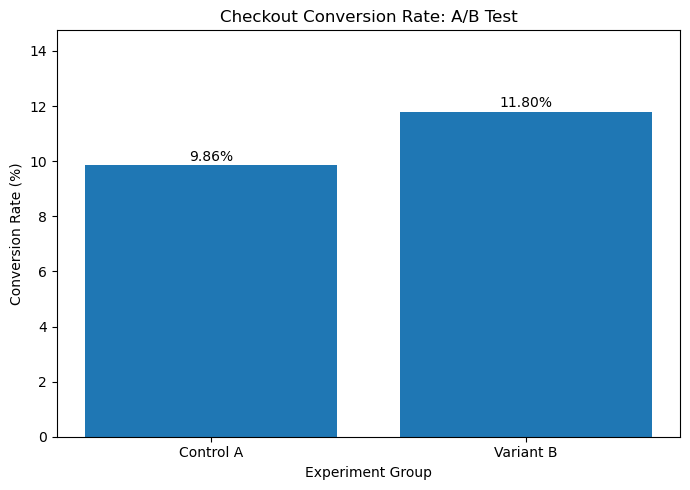

In [13]:

# Visualization 1: Conversion Rate Comparison

conversion_rates = (
    df.groupby("group")["converted"]
    .mean()
    .mul(100)
    .reindex(["A", "B"])
)

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["Control A", "Variant B"],
    conversion_rates.values
)

plt.title("Checkout Conversion Rate: A/B Test")
plt.ylabel("Conversion Rate (%)")
plt.xlabel("Experiment Group")
plt.ylim(0, max(conversion_rates.values) * 1.25)

for bar, rate in zip(bars, conversion_rates.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{rate:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


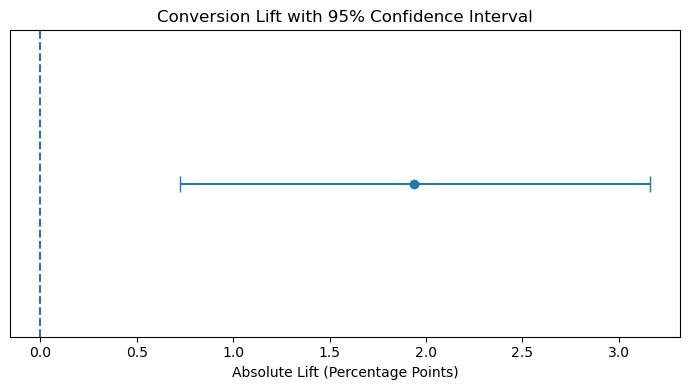

Observed lift: 1.94 percentage points
95% CI: [0.72, 3.16] percentage points


In [14]:

# Visualization 2: Conversion Lift and 95% Confidence Interval

from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    count1=int(conversions[1]),  # Variant B conversions
    nobs1=int(users[1]),         # Variant B users
    count2=int(conversions[0]),  # Control A conversions
    nobs2=int(users[0]),         # Control A users
    method="newcomb",
    compare="diff",
    alpha=0.05
)

observed_lift = absolute_lift * 100

plt.figure(figsize=(7, 4))
plt.errorbar(
    x=observed_lift,
    y=0,
    xerr=[[
        observed_lift - ci_low * 100
    ], [
        ci_high * 100 - observed_lift
    ]],
    fmt="o",
    capsize=6
)

plt.axvline(0, linestyle="--")
plt.title("Conversion Lift with 95% Confidence Interval")
plt.xlabel("Absolute Lift (Percentage Points)")
plt.yticks([])
plt.tight_layout()
plt.show()

print(f"Observed lift: {observed_lift:.2f} percentage points")
print(
    f"95% CI: [{ci_low * 100:.2f}, "
    f"{ci_high * 100:.2f}] percentage points"
)


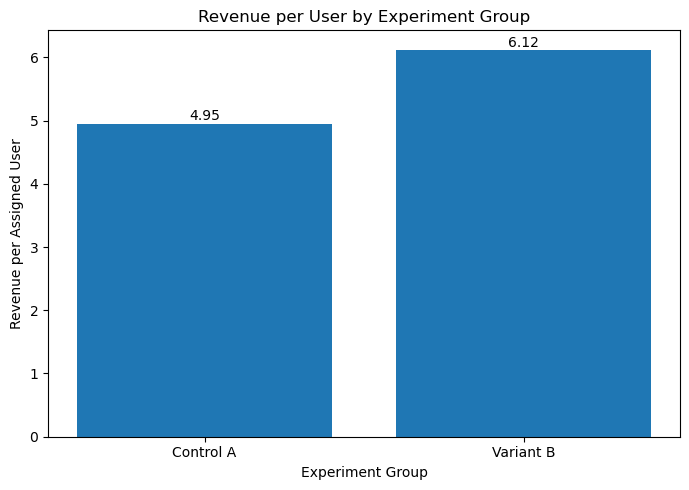

In [15]:

# Visualization 3: Revenue per Assigned User

revenue_per_user = (
    df.groupby("group")["order_value"]
    .mean()
    .reindex(["A", "B"])
)

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["Control A", "Variant B"],
    revenue_per_user.values
)

plt.title("Revenue per User by Experiment Group")
plt.ylabel("Revenue per Assigned User")
plt.xlabel("Experiment Group")

for bar, value in zip(bars, revenue_per_user.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


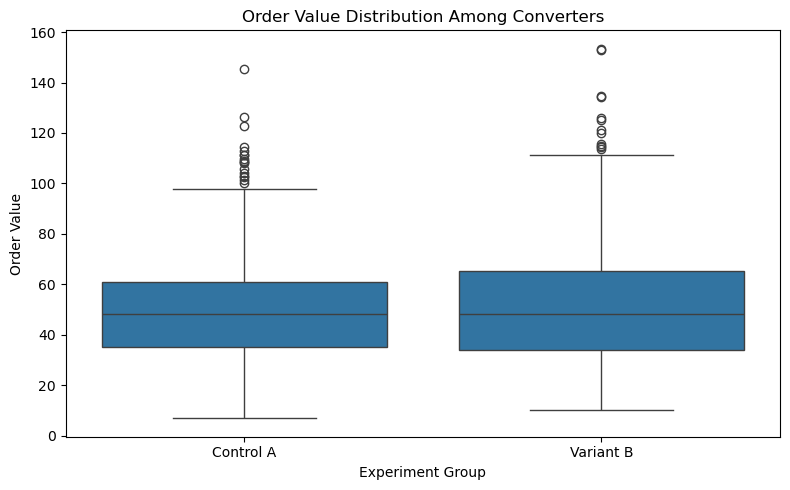

In [16]:

# Visualization 4: Order Value Distribution Among Converters

converted_users = df[df["converted"] == 1]

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=converted_users,
    x="group",
    y="order_value",
    order=["A", "B"]
)

plt.title("Order Value Distribution Among Converters")
plt.xlabel("Experiment Group")
plt.ylabel("Order Value")
plt.xticks([0, 1], ["Control A", "Variant B"])

plt.tight_layout()
plt.show()


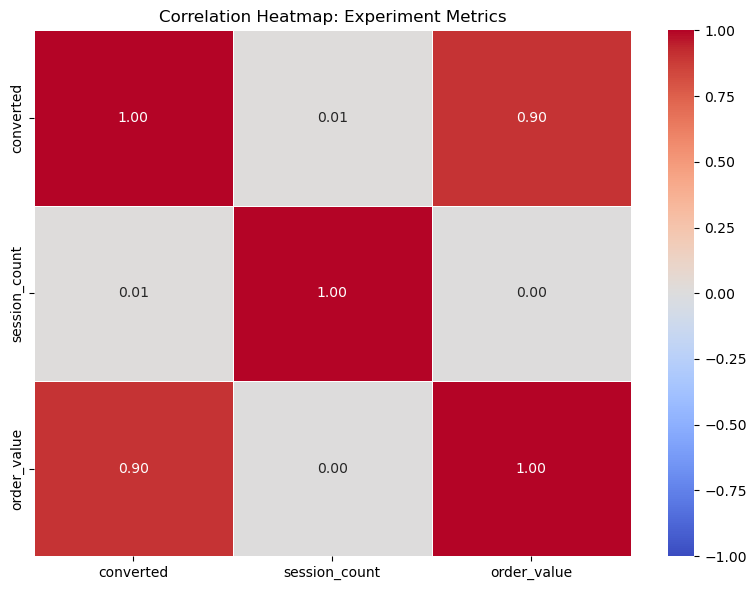

In [17]:

# Visualization 5: Correlation Heatmap

numeric_cols = [
    "converted",
    "session_count",
    "order_value"
]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap: Experiment Metrics")
plt.tight_layout()
plt.show()


In [18]:

# Experiment validity checks

print("Total unique users:", df["user_id"].nunique())
print("Total records:", len(df))

print("\nGroup allocation:")
print(df["group"].value_counts().sort_index())

print("\nConversion outcomes by group:")
print(
    pd.crosstab(
        df["group"],
        df["converted"],
        margins=True
    )
)

print("\nSession count summary by group:")
print(
    df.groupby("group")["session_count"]
    .describe()
    .round(2)
)


Total unique users: 10000
Total records: 10000

Group allocation:
group
A    5000
B    5000
Name: count, dtype: int64

Conversion outcomes by group:
converted     0     1    All
group                       
A          4507   493   5000
B          4410   590   5000
All        8917  1083  10000

Session count summary by group:
        count  mean   std  min  25%  50%  75%  max
group                                             
A      5000.0  1.70  0.89  1.0  1.0  1.0  2.0  4.0
B      5000.0  1.72  0.91  1.0  1.0  1.0  2.0  4.0


In [19]:

from scipy.stats import chisquare

# Expected allocation: 50% Control A, 50% Variant B
observed_users = (
    df["group"]
    .value_counts()
    .reindex(["A", "B"])
    .to_numpy()
)

expected_users = np.array([5000, 5000])

srm_stat, srm_p_value = chisquare(
    f_obs=observed_users,
    f_exp=expected_users
)

print("Observed group sizes:", observed_users)
print("Expected group sizes:", expected_users)
print(f"Chi-square statistic: {srm_stat:.4f}")
print(f"SRM p-value: {srm_p_value:.4f}")

if srm_p_value < 0.05:
    print("Warning: Evidence of a sample ratio mismatch.")
else:
    print("No evidence of a sample ratio mismatch.")


Observed group sizes: [5000 5000]
Expected group sizes: [5000 5000]
Chi-square statistic: 0.0000
SRM p-value: 1.0000
No evidence of a sample ratio mismatch.


In [20]:

# Bootstrap confidence interval for revenue per user difference

rng = np.random.default_rng(42)

revenue_a = df.loc[df["group"] == "A", "order_value"].to_numpy()
revenue_b = df.loc[df["group"] == "B", "order_value"].to_numpy()

N_BOOTSTRAPS = 5000
bootstrap_differences = np.empty(N_BOOTSTRAPS)

for i in range(N_BOOTSTRAPS):
    sample_a = rng.choice(revenue_a, size=len(revenue_a), replace=True)
    sample_b = rng.choice(revenue_b, size=len(revenue_b), replace=True)

    bootstrap_differences[i] = sample_b.mean() - sample_a.mean()

ci_low_revenue, ci_high_revenue = np.percentile(
    bootstrap_differences, [2.5, 97.5]
)

observed_revenue_difference = revenue_b.mean() - revenue_a.mean()

print(f"Observed revenue per user difference: {observed_revenue_difference:.4f}")
print(
    "95% bootstrap confidence interval: "
    f"[{ci_low_revenue:.4f}, {ci_high_revenue:.4f}]"
)

if ci_low_revenue > 0:
    print("Interpretation: The interval suggests higher revenue per user in Variant B.")
elif ci_high_revenue < 0:
    print("Interpretation: The interval suggests lower revenue per user in Variant B.")
else:
    print("Interpretation: The interval includes zero; the difference is inconclusive.")


Observed revenue per user difference: 1.1679
95% bootstrap confidence interval: [0.4898, 1.8401]
Interpretation: The interval suggests higher revenue per user in Variant B.


In [21]:

# Conversion rate by session count and experiment group

session_conversion = (
    df.groupby(["session_count", "group"])["converted"]
    .mean()
    .mul(100)
    .unstack()
    .reindex(columns=["A", "B"])
)

session_conversion.columns = ["Control A (%)", "Variant B (%)"]

display(session_conversion.round(2))


,Control A (%),Variant B (%)
session_count,,
1,9.33,11.71
2,10.71,11.38
3,10.22,13.05
4,10.08,11.07


In [22]:

# Absolute and relative conversion lift by session count

session_lift = session_conversion.copy()

session_lift["Absolute lift (pp)"] = (
    session_lift["Variant B (%)"] - session_lift["Control A (%)"]
)

session_lift["Relative lift (%)"] = (
    session_lift["Absolute lift (pp)"]
    / session_lift["Control A (%)"]
    * 100
)

display(session_lift.round(2))


,Control A (%),Variant B (%),Absolute lift (pp),Relative lift (%)
session_count,,,,
1,9.33,11.71,2.37,25.42
2,10.71,11.38,0.67,6.27
3,10.22,13.05,2.83,27.71
4,10.08,11.07,0.98,9.76
